# ML ASSIGNMENT - B1

Predict the price of the Uber ride from a given pickup point to the agreed drop-off location. 
Perform following tasks: 
1. Pre-process the dataset. 
2. Identify outliers. 
3. Check the correlation. 
4. Implement linear regression and random forest regression models. 

Evaluate the models and compare their respective scores like R2, RMSE, etc.  

**Dataset link: Uber Fares Dataset (Kaggle)**  
https://www.kaggle.com/datasets/yasserh/uber-fares-dataset 

### 1) Import libraries

In [309]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2) Load Dataset

In [310]:
df = pd.read_csv("uber.csv")

In [311]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [312]:
df.shape

(200000, 9)

In [313]:
df.dtypes

Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [314]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [315]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


### 3) Preprocessing

**3.1) Remove first two columns**

In [316]:
df.drop(columns=["Unnamed: 0", "key"], inplace=True, errors="ignore")

In [317]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


**3.2) Handle Missing Values**

In [318]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [319]:
df.dropna(inplace=True)

In [320]:
df.isnull().sum()

fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

**3.3) Convert pickup_datetime datatype from object to datetime64**

In [321]:
df["pickup_datetime"] = pd.to_datetime(
    df["pickup_datetime"], errors="coerce", utc=True
)

In [322]:
df.dtypes

fare_amount                      float64
pickup_datetime      datetime64[ns, UTC]
pickup_longitude                 float64
pickup_latitude                  float64
dropoff_longitude                float64
dropoff_latitude                 float64
passenger_count                    int64
dtype: object

**3.4) Extract date and time features**

In [323]:
df["hour"] = df["pickup_datetime"].dt.hour
df["day"] = df["pickup_datetime"].dt.day
df["month"] = df["pickup_datetime"].dt.month
df["year"] = df["pickup_datetime"].dt.year
df["dayofweek"] = df["pickup_datetime"].dt.dayofweek

df.drop(columns=["pickup_datetime"], inplace=True)

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3


<b>2.5) Remove invalid records</b>

In [330]:
df = df[
    (df["fare_amount"] > 0) &
    (df["passenger_count"] > 0) &
    (df["passenger_count"] <= 6) &
    (df["pickup_latitude"].between(-90, 90)) &
    (df["dropoff_latitude"].between(-90, 90)) &
    (df["pickup_longitude"].between(-180, 180)) &
    (df["dropoff_longitude"].between(-180, 180))
].copy()

print(df.isnull().sum())

print("\nDataset shape after preprocessing:", df.shape)

fare_amount          0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
hour                 0
day                  0
month                0
year                 0
dayofweek            0
dtype: int64

Dataset shape after preprocessing: (199256, 11)


### 4) Calculate distance between pickup and drop-off
We use the Haversine formula to calculate the approximate straight-line distance between two geographical coordinates.

In [331]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371  # Radius of Earth in km

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (np.sin(dlat / 2) ** 2 +
         np.cos(lat1) * np.cos(lat2) *
         np.sin(dlon / 2) ** 2)

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


df["distance_km"] = haversine(
    df["pickup_latitude"],
    df["pickup_longitude"],
    df["dropoff_latitude"],
    df["dropoff_longitude"]
)

# Remove zero-distance and extremely long trips
df = df[
    (df["distance_km"] > 0) &
    (df["distance_km"] < 100)
].copy()

df.head()

,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day,month,year,dayofweek,distance_km
0,7.5,-73.999817,40.738354,-73.999512,40.723217,1,19,7,5,2015,3,1.683323
1,7.7,-73.994355,40.728225,-73.994710,40.750325,1,20,17,7,2009,4,2.457590
2,12.9,-74.005043,40.740770,-73.962565,40.772647,1,21,24,8,2009,0,5.036377
3,5.3,-73.976124,40.790844,-73.965316,40.803349,3,8,26,6,2009,4,1.661683
4,16.0,-73.925023,40.744085,-73.973082,40.761247,5,17,28,8,2014,3,4.475450


### 5) Identify and remove outliers
Use the Interquartile Range (IQR) method.

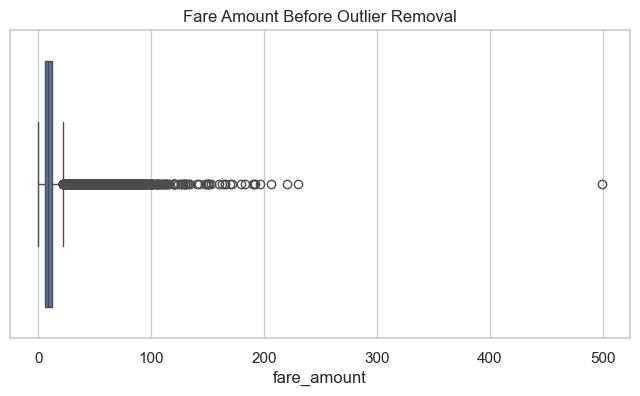

Lower Bound: -3.75
Upper Bound: 22.25


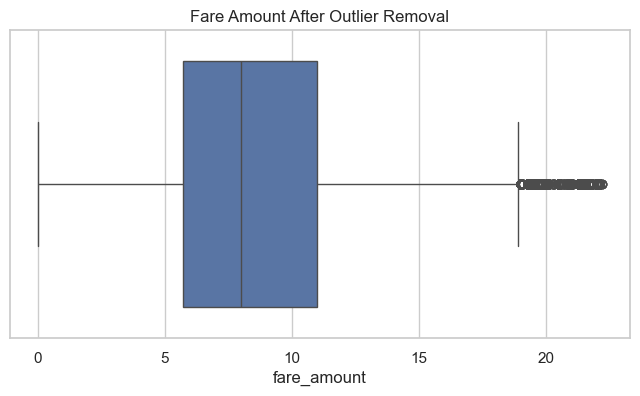

Dataset shape after removing outliers: (176651, 12)


In [332]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount Before Outlier Removal")
plt.show()

Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

df = df[
    (df["fare_amount"] >= lower_bound) &
    (df["fare_amount"] <= upper_bound)
].copy()

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["fare_amount"])
plt.title("Fare Amount After Outlier Removal")
plt.show()

print("Dataset shape after removing outliers:", df.shape)

### 6) Check correlation

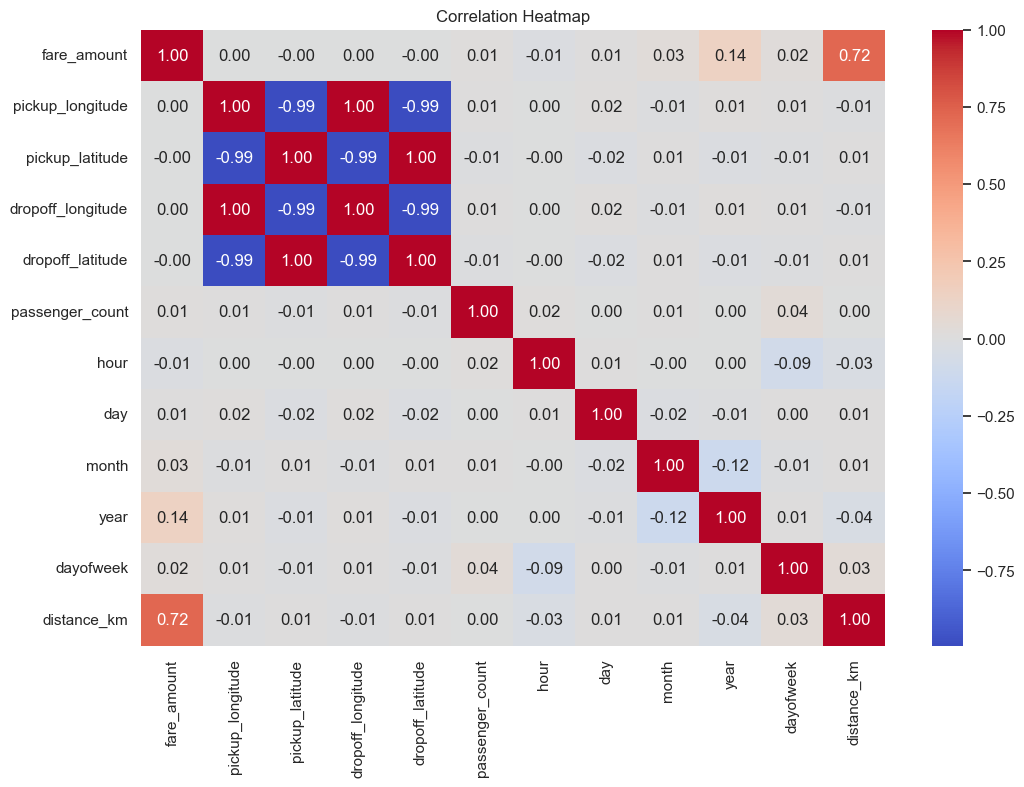

fare_amount          1.000000
distance_km          0.723498
year                 0.135745
month                0.026705
dayofweek            0.020356
passenger_count      0.013017
day                  0.006575
dropoff_longitude    0.002047
pickup_longitude     0.001204
pickup_latitude     -0.002014
dropoff_latitude    -0.002214
hour                -0.013121
Name: fare_amount, dtype: float64


In [333]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

print(
    df.corr(numeric_only=True)["fare_amount"]
    .sort_values(ascending=False)
)

### 7) Select features and split the dataset (80:20)

In [334]:
X = df.drop(columns=["fare_amount"])
y = df["fare_amount"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

### 8) Implement Linear Regression

In [335]:
lr = LinearRegression()

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

r2_lr = np.round(r2_score(y_test, y_pred_lr), 2)
rmse_lr = np.round(np.sqrt(mean_squared_error(y_test, y_pred_lr)), 2)

print("Predictions")
print(y_pred_lr)

print("\nLinear Regression Results")
print("R2 Score:", r2_lr)
print("RMSE:", rmse_lr)

Predictions
[6.12329682 7.1264912  7.92071999 ... 7.74379525 8.12429794 7.52575194]

Linear Regression Results
R2 Score: 0.62
RMSE: 2.55


### 9) Implement Random Forest Regression

In [336]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

r2_rf = np.round(r2_score(y_test, y_pred_rf), 2)
rmse_rf = np.round(np.sqrt(mean_squared_error(y_test, y_pred_rf)), 2)

print("Predictions")
print(y_pred_rf)

print("\nRandom Forest Regression Results")
print("R2 Score:", r2_rf)
print("RMSE:", rmse_rf)

Predictions
[5.641 5.81  7.561 ... 7.494 7.68  5.954]

Random Forest Regression Results
R2 Score: 0.78
RMSE: 1.94


### 10) Compare model performance

In [337]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "R2 Score": [r2_lr, r2_rf],
    "RMSE": [rmse_lr, rmse_rf]
})

print(results)

               Model  R2 Score  RMSE
0  Linear Regression      0.62  2.55
1      Random Forest      0.78  1.94
